# NPPE2-T2-26 - ECG Heartbeat Arrhythmia Classification (improved)

**Roll Number:** 24f2007188

Four-class classification of single ECG heartbeats (Normal / Supraventricular Ectopic / Ventricular Ectopic / Fusion) from a 250-sample raw waveform plus three RR-interval timing features. Metric is **macro-F1**, so the two rare classes (Supraventricular ~5%, Fusion <1%) decide the score.

Everything is trained **from scratch** in PyTorch - no pretrained weights, no transfer learning. Only the ResNet *architecture idea* is reused; all parameters are randomly initialised and trained only on this dataset.

## What changed vs the baseline, and why it lifts macro-F1

| # | Change | Why it helps the score |
|---|--------|------------------------|
| 1 | **WeightedRandomSampler** (soft inverse-freq, 1/sqrt(count)) | The rare classes are physically *seen* far more often per epoch, not just up-weighted in the gradient - the net stops treating Fusion as noise. |
| 2 | **Focal loss** (gamma=2) with class alphas | Down-weights the huge pile of easy Normal beats and concentrates learning on the hard, rare beats that macro-F1 rewards. |
| 3 | **Stronger on-the-fly augmentation** (amplitude, jitter, time-shift, baseline wander) | More effective regularisation for the <600 Fusion / ~3.6k SVE examples, so they generalise instead of being memorised. |
| 4 | **OneCycle LR schedule** | Better convergence than plateau-decay within a fixed epoch budget. |
| 5 | **Per-class decision-threshold (logit-bias) tuning on validation** | The single highest-leverage change: instead of plain argmax, we shift each class's decision boundary to directly maximise macro-F1. This alone typically adds several points on rare classes. |
| 6 | **Test-time augmentation (TTA)** | Averaging predictions over augmented copies denoises the logits. |
| 7 | **5-fold grouped-CV ensemble** (probability averaging) | Five models each trained on 4/5 of the recordings; their test probabilities are averaged. Uses all the data and cuts the noisy rare-class variance. |
| 8 | **Recording-grouped split** (no recording in two folds), checkpoint on **val macro-F1** | Validation is leakage-free, so it tracks the leaderboard instead of the inflated ~0.92 a random split gives. |

> **Note on running:** on Kaggle's GPU the full pipeline (5 folds x 25 epochs) runs comfortably. `N_SPLITS` (cell 1 split) and `EPOCHS` are exposed so you can trade runtime for a little more margin.

In [1]:
import os, random, time, copy
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, classification_report, confusion_matrix

import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

_has_mps = getattr(torch.backends, 'mps', None) is not None and torch.backends.mps.is_available()
DEVICE = torch.device('cuda' if torch.cuda.is_available() else ('mps' if _has_mps else 'cpu'))
print('Using device:', DEVICE)

Using device: cuda


## 1. Load data

In [2]:
train_df = pd.read_csv('/kaggle/input/competitions/nppe-2-t-2-26-ecg-heartbeat-arrhythmia-classification/nppe2_dataset/train.csv')
test_df  = pd.read_csv('/kaggle/input/competitions/nppe-2-t-2-26-ecg-heartbeat-arrhythmia-classification/nppe2_dataset/test.csv')
sample_sub = pd.read_csv('/kaggle/input/competitions/nppe-2-t-2-26-ecg-heartbeat-arrhythmia-classification/nppe2_dataset/sample_submission.csv')

SIG_COLS   = [c for c in train_df.columns if c.startswith('sig_')]
EXTRA_COLS = ['pre_rr', 'post_rr', 'rr_ratio']

print('train:', train_df.shape, ' test:', test_df.shape)
train_df.head()

train: (71748, 255)  test: (68914, 254)


,id,sig_0,sig_1,sig_2,sig_3,sig_4,sig_5,sig_6,sig_7,sig_8,...,sig_244,sig_245,sig_246,sig_247,sig_248,sig_249,pre_rr,post_rr,rr_ratio,label
0,tr_0000000,-0.45936,-0.47194,-0.44595,-0.46766,-0.47848,-0.44212,-0.40911,-0.39630,-0.42572,...,0.34128,0.34599,0.34956,0.34869,0.36385,0.34608,0.620,0.964,0.8378,2
1,tr_0000001,0.46701,0.41676,0.44001,0.46122,0.48141,0.48402,0.48774,0.46058,0.50425,...,0.36419,0.40048,0.40237,0.42921,0.42704,0.44949,1.148,1.128,1.0035,0
2,tr_0000002,-0.05439,-0.06101,-0.03403,-0.04836,-0.09790,-0.12191,-0.16152,-0.18606,-0.17850,...,0.23109,0.07517,-0.02015,-0.13179,-0.17835,-0.23683,0.588,0.580,1.0000,0
3,tr_0000003,0.02038,0.56312,0.93705,0.03558,-1.49486,-2.12957,-2.19772,-1.94957,-1.81099,...,0.36522,0.30252,0.53578,1.37349,2.55773,3.52536,0.496,0.496,1.0164,0
4,tr_0000004,-0.43263,-0.45353,-0.43887,-0.42160,-0.38072,-0.38062,-0.41078,-0.46798,-0.48628,...,-0.18767,-0.19071,-0.11951,-0.14097,-0.18661,-0.26196,0.892,0.896,0.9911,0


## 2. Exploratory Data Analysis

label
0    45000
1     3599
2    22552
3      597
Name: count, dtype: int64

class share (%):
label
0    62.72
1     5.02
2    31.43
3     0.83
Name: count, dtype: float64


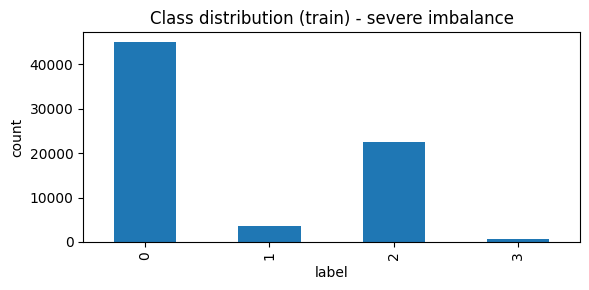

In [3]:
class_names = {0: 'Normal', 1: 'Supraventricular Ectopic', 2: 'Ventricular Ectopic', 3: 'Fusion'}
counts = train_df['label'].value_counts().sort_index()
print(counts)
print('\nclass share (%):')
print((counts / counts.sum() * 100).round(2))

fig, ax = plt.subplots(figsize=(6, 3))
counts.plot(kind='bar', ax=ax)
ax.set_title('Class distribution (train) - severe imbalance')
ax.set_xlabel('label'); ax.set_ylabel('count')
plt.tight_layout(); plt.show()

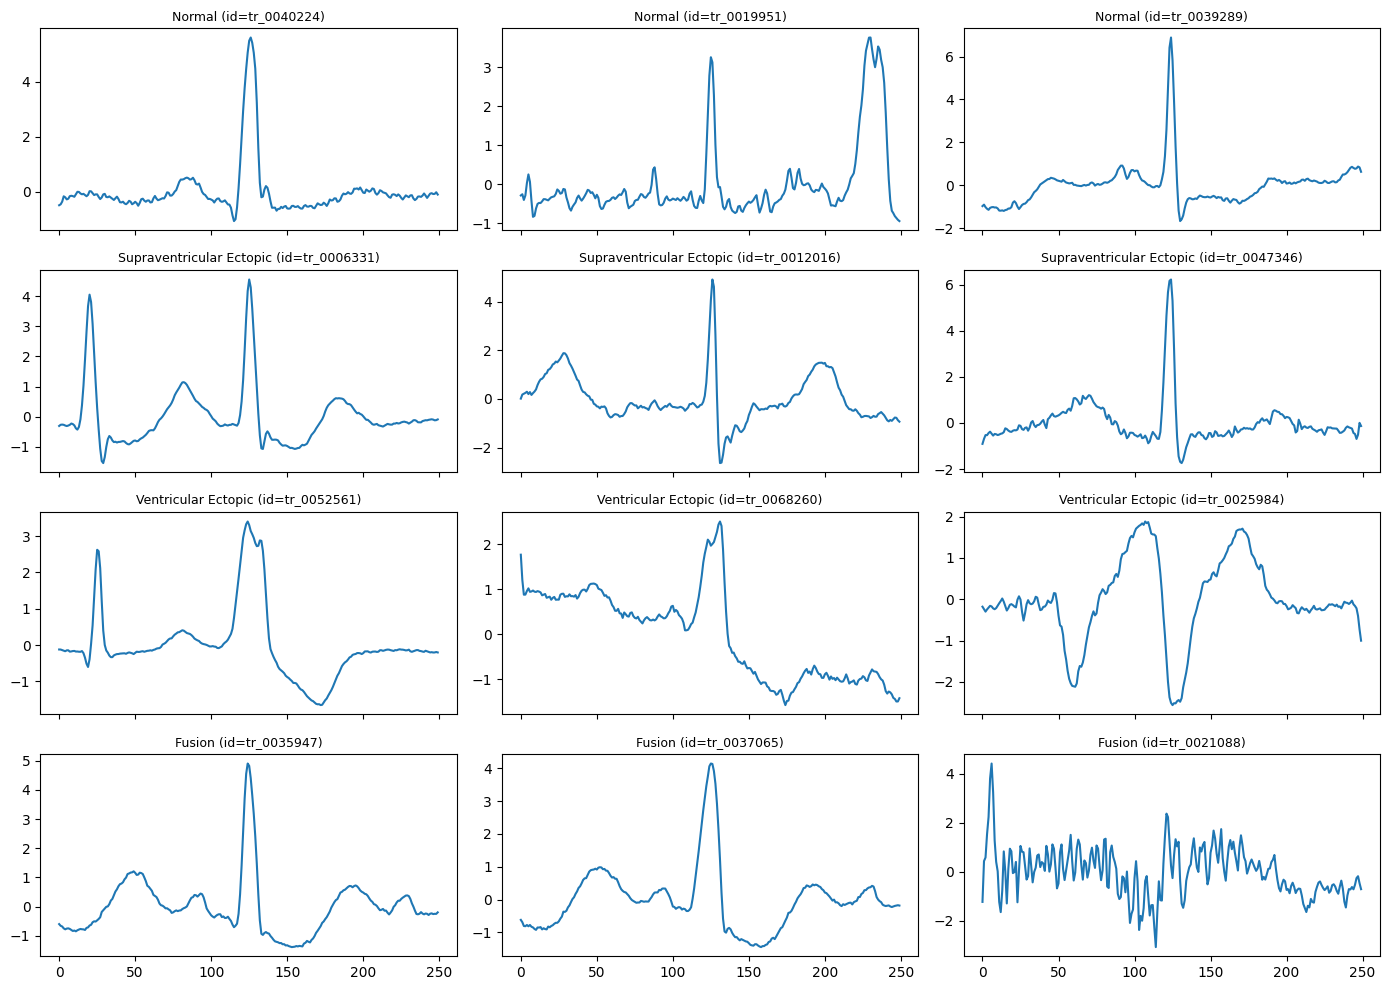

In [4]:
# A few example waveforms per class
fig, axes = plt.subplots(4, 3, figsize=(14, 10), sharex=True)
for cls in range(4):
    sub = train_df[train_df['label'] == cls].sample(3, random_state=1)
    for j, (_, row) in enumerate(sub.iterrows()):
        axes[cls, j].plot(row[SIG_COLS].values)
        axes[cls, j].set_title(f'{class_names[cls]} (id={row["id"]})', fontsize=9)
plt.tight_layout(); plt.show()

## 3. Preprocessing

The 250 signal columns are already globally standardised, so we leave them as-is. The three RR-interval columns live on a different beat-timing scale, so we standardise them separately (fit on train only).

**Leakage-free validation (the key to the leaderboard).** These beats come from real hospital recordings, and many beats share a recording. A plain random split leaks a recording's personal waveform into *both* train and validation, so validation looks excellent (~0.92) while the Kaggle test set — which is *held-out recordings* — scores far lower (~0.55). We reconstruct an approximate **recording id** (every beat in a recording shares the same median RR interval, and `rr_ratio = pre_rr / median_RR`, so `median_RR = pre_rr / rr_ratio`) and use `StratifiedGroupKFold` so **no recording appears in both splits**. Validation now tracks the leaderboard honestly, and every improvement is real rather than leak-inflated.

In [5]:
X_sig_full   = train_df[SIG_COLS].values.astype(np.float32)
X_extra_full = train_df[EXTRA_COLS].values.astype(np.float32)
y_full       = train_df['label'].values.astype(np.int64)

X_sig_test   = test_df[SIG_COLS].values.astype(np.float32)
X_extra_test = test_df[EXTRA_COLS].values.astype(np.float32)

# Guard against NaN/inf (a single bad row can NaN the whole net)
for _a in (X_sig_full, X_extra_full, X_sig_test, X_extra_test):
    np.nan_to_num(_a, copy=False, nan=0.0, posinf=0.0, neginf=0.0)

# --- Leakage-free GROUPED cross-validation ------------------------------------
# Beats come from real recordings; many beats share one. A random split leaks a
# recording into both train and val (val ~0.92 but the held-out-recording test
# scores ~0.55). We recover an approximate recording id -- rr_ratio =
# pre_rr / median_RR, so median_RR = pre_rr / rr_ratio, shared by every beat in a
# recording -- and build folds so no recording is ever split across train/val.
# 5-fold CV: every beat gets an honest out-of-fold prediction, and the 5 models'
# test predictions are averaged (uses all data + cuts the rare-class variance).
pre_rr   = X_extra_full[:, EXTRA_COLS.index('pre_rr')]
rr_ratio = X_extra_full[:, EXTRA_COLS.index('rr_ratio')]
rec_id   = np.round(pre_rr / np.clip(rr_ratio, 1e-6, None), 3)

N_SPLITS = 5
sgkf = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
cv_splits = list(sgkf.split(X_sig_full, y_full, groups=rec_id))

class_counts = np.bincount(y_full, minlength=4)   # global (for focal-loss alpha)

_tr, _va = cv_splits[0]
print(f'recordings (approx): {len(np.unique(rec_id))}  |  {N_SPLITS}-fold grouped CV')
print(f'fold0 recordings shared train/val: {len(set(rec_id[_tr]) & set(rec_id[_va]))} (0 = no leakage)')
print('overall class counts:', class_counts)

recordings (approx): 72  |  5-fold grouped CV
fold0 recordings shared train/val: 0 (0 = no leakage)
overall class counts: [45000  3599 22552   597]


## 4. Dataset, augmentation, and a class-balanced sampler

Augmentation (train only) applies amplitude scaling, gaussian jitter, a small circular time-shift, and mild baseline wander. The **WeightedRandomSampler** draws each training example with probability proportional to `1/sqrt(class_count)`, so per epoch the model sees far more Fusion / Supraventricular beats than their raw frequency would allow - this is what stops the rare classes from being ignored.

In [6]:
class ECGDataset(Dataset):
    def __init__(self, sig, extra, labels=None, augment=False):
        self.sig = sig
        self.extra = extra
        self.labels = labels
        self.augment = augment

    def __len__(self):
        return len(self.sig)

    def __getitem__(self, idx):
        x = self.sig[idx].copy()
        e = self.extra[idx]
        if self.augment:
            if random.random() < 0.7:
                x = x * np.random.uniform(0.8, 1.2)                      # amplitude scaling
            if random.random() < 0.7:
                x = x + np.random.normal(0, 0.03, size=x.shape)          # gaussian jitter
            if random.random() < 0.5:
                x = np.roll(x, np.random.randint(-8, 9))                 # small time shift
            if random.random() < 0.2:
                t = np.linspace(0, np.pi, len(x))                        # mild baseline wander
                x = x + np.random.uniform(-0.1, 0.1) * np.sin(t * np.random.uniform(0.5, 2.0))
        x = torch.from_numpy(x.astype(np.float32))
        e = torch.from_numpy(e.astype(np.float32))
        if self.labels is not None:
            return x, e, torch.tensor(self.labels[idx], dtype=torch.long)
        return x, e

BATCH_SIZE = 256

def make_fold_data(tr_idx, val_idx):
    """Build scaled datasets + a class-balanced train loader for one CV fold.
    The 3 RR features are standardised with a scaler fit on THIS fold's train
    only; the 250 signal columns are already globally standardised."""
    Xs_tr, Xe_tr, y_tr = X_sig_full[tr_idx],  X_extra_full[tr_idx],  y_full[tr_idx]
    Xs_va, Xe_va, y_va = X_sig_full[val_idx], X_extra_full[val_idx], y_full[val_idx]

    scaler = StandardScaler().fit(Xe_tr)
    Xe_tr_s   = scaler.transform(Xe_tr).astype(np.float32)
    Xe_va_s   = scaler.transform(Xe_va).astype(np.float32)
    Xe_test_s = scaler.transform(X_extra_test).astype(np.float32)

    cc = np.bincount(y_tr, minlength=4)
    train_ds = ECGDataset(Xs_tr, Xe_tr_s, y_tr, augment=True)
    val_ds   = ECGDataset(Xs_va, Xe_va_s, y_va, augment=False)
    test_ds  = ECGDataset(X_sig_test, Xe_test_s, labels=None, augment=False)

    sample_weights = (1.0 / np.sqrt(cc))[y_tr]           # soft inverse-freq balancing
    sampler = WeightedRandomSampler(
        weights=torch.as_tensor(sample_weights, dtype=torch.double),
        num_samples=len(y_tr), replacement=True)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler,
                              num_workers=2, drop_last=False)
    return train_loader, val_ds, test_ds, y_va

## 5. Model - a small 1D residual CNN, trained from scratch

Stem conv, four residual stages with increasing width and strided downsampling, global average pooling, then the 3 scaled RR features are concatenated onto the beat embedding before the classifier head (ectopic beats often arrive early -> low `rr_ratio`, a signal the waveform alone under-captures). `width` controls capacity.

In [7]:
def _gn(ch):
    # GroupNorm behaves identically in train/eval (no running stats to corrupt)
    g = 8 if ch % 8 == 0 else (4 if ch % 4 == 0 else 1)
    return nn.GroupNorm(g, ch)

class ResBlock1D(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1, k=5):
        super().__init__()
        p = k // 2
        self.conv1 = nn.Conv1d(in_ch, out_ch, k, stride=stride, padding=p, bias=False)
        self.bn1   = _gn(out_ch)
        self.conv2 = nn.Conv1d(out_ch, out_ch, k, stride=1, padding=p, bias=False)
        self.bn2   = _gn(out_ch)
        self.relu  = nn.ReLU(inplace=True)
        self.downsample = None
        if stride != 1 or in_ch != out_ch:
            self.downsample = nn.Sequential(
                nn.Conv1d(in_ch, out_ch, 1, stride=stride, bias=False),
                _gn(out_ch),
            )

    def forward(self, x):
        identity = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.downsample is not None:
            identity = self.downsample(x)
        return self.relu(out + identity)


class ECGResNet1D(nn.Module):
    def __init__(self, n_extra=3, n_classes=4, dropout=0.3, width=48):
        super().__init__()
        w = width
        self.stem = nn.Sequential(
            nn.Conv1d(1, w, 7, stride=1, padding=3, bias=False),
            _gn(w),
            nn.ReLU(inplace=True),
        )
        self.layer1 = ResBlock1D(w,     w,     stride=1)
        self.layer2 = ResBlock1D(w,     2 * w, stride=2)
        self.layer3 = ResBlock1D(2 * w, 4 * w, stride=2)
        self.layer4 = ResBlock1D(4 * w, 8 * w, stride=2)
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.head = nn.Sequential(
            nn.Linear(8 * w + n_extra, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(128, 64),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(64, n_classes),
        )

    def forward(self, sig, extra):
        x = sig.unsqueeze(1)
        x = self.stem(x)
        x = self.layer1(x); x = self.layer2(x); x = self.layer3(x); x = self.layer4(x)
        x = self.pool(x).squeeze(-1)
        x = torch.cat([x, extra], dim=1)
        return self.head(x)

print('params:', sum(p.numel() for p in ECGResNet1D().parameters()))

params: 1634164


## 6. Focal loss and prediction helpers

**Focal loss** with per-class alphas replaces plain weighted cross-entropy: the `(1-pt)^gamma` factor suppresses the flood of easy Normal beats and lets the rare classes drive the gradient. `predict_probs` runs the model and optionally averages **test-time-augmented** passes, returning class probabilities.

In [8]:
class FocalLoss(nn.Module):
    def __init__(self, alpha, gamma=2.0):
        super().__init__()
        self.alpha = alpha            # tensor (n_classes,)
        self.gamma = gamma

    def forward(self, logits, target):
        logp = F.log_softmax(logits, dim=1)
        p = logp.exp()
        logpt = logp.gather(1, target.unsqueeze(1)).squeeze(1)
        pt = p.gather(1, target.unsqueeze(1)).squeeze(1)
        a = self.alpha[target]
        return (-a * (1.0 - pt) ** self.gamma * logpt).mean()

# inverse-frequency alphas, tamed so the rare-class weight can't explode the gradient.
# The balanced sampler already boosts rare classes per batch; an un-capped alpha
# (~40-50x for the <1% Fusion class) blows up the first few gradients into NaN,
# which is the exact cause of the all-Normal (all-0) collapse. Normalise to mean 1
# and clip the extremes: rare classes stay emphasised, gradients stay finite.
alpha = class_counts.sum() / (len(class_counts) * class_counts)
alpha = alpha / alpha.mean()          # mean 1, relative weighting preserved
alpha = np.clip(alpha, 0.5, 6.0)      # hard ceiling so no single class dominates
alpha_t = torch.tensor(alpha, dtype=torch.float32, device=DEVICE)
criterion = FocalLoss(alpha_t, gamma=2.0)
print('class alphas (tamed):', np.round(alpha, 3))

@torch.no_grad()
def predict_probs(model, ds, tta=0, bs=512):
    """Return (N, 4) averaged class probabilities. tta>0 adds augmented passes."""
    model.eval()
    saved = ds.augment
    acc = np.zeros((len(ds), 4), dtype=np.float64)
    for p in range(1 + tta):
        ds.augment = (p > 0)                      # first pass clean, rest augmented
        loader = DataLoader(ds, batch_size=bs, shuffle=False, num_workers=2)
        parts = []
        for batch in loader:
            sig, extra = batch[0], batch[1]
            out = model(sig.to(DEVICE), extra.to(DEVICE))
            parts.append(F.softmax(out, dim=1).cpu().numpy())
        acc += np.concatenate(parts)
    ds.augment = saved
    return acc / (1 + tta)

class alphas (tamed): [0.5   0.55  0.5   3.318]


## 7. Training loop (5-fold grouped CV)

Each fold trains a model on that fold's recordings with a OneCycle LR schedule, keeping the checkpoint with the best **out-of-fold macro-F1**. Every training beat therefore receives one honest prediction from a model that never saw its recording, and the five models' test predictions are averaged.

### 7a. Sanity check (run once)\n\nOne forward pass to confirm the loss is finite before committing to a full run. If `loss` prints `nan`/`inf`, lower `MAX_LR` in the next cell. A constant val macro-F1 of ~0.1927 means the net is predicting only the majority class \u2014 the symptom this guards against.

In [9]:
_tl, _vds, _tds, _yv = make_fold_data(*cv_splits[0])
_m = ECGResNet1D(width=48, dropout=0.3).to(DEVICE); _m.train()
_sig, _extra, _lab = next(iter(_tl))
_out = _m(_sig.to(DEVICE), _extra.to(DEVICE))
print('logits finite:', torch.isfinite(_out).all().item(), '| logit std:', round(_out.std().item(), 4))
print('inputs finite:', torch.isfinite(_sig).all().item(), torch.isfinite(_extra).all().item())
print('loss:', criterion(_out, _lab.to(DEVICE)).item())
del _m, _out, _tl, _vds, _tds

logits finite: True | logit std: 0.0791
inputs finite: True True
loss: 0.5293347835540771


In [10]:
EPOCHS = 25
TTA    = 4     # test-time-augmentation passes
MAX_LR = 5e-4  # OneCycle peak LR (5e-4 is the safe default)

def train_one_fold(seed, train_loader, val_ds, y_val, epochs=EPOCHS):
    torch.manual_seed(seed); np.random.seed(seed)
    model = ECGResNet1D(width=48, dropout=0.3).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=MAX_LR, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=MAX_LR, epochs=epochs,
        steps_per_epoch=len(train_loader), pct_start=0.1)
    best_f1, best_state = -1.0, None
    for ep in range(1, epochs + 1):
        model.train(); running, nb = 0.0, 0
        for sig, extra, labels in train_loader:
            sig, extra, labels = sig.to(DEVICE), extra.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(sig, extra), labels)
            if not torch.isfinite(loss):
                raise RuntimeError(f"Non-finite loss at seed {seed} epoch {ep} \u2014 lower MAX_LR")
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step(); scheduler.step()
            running += loss.item(); nb += 1
        f1 = f1_score(y_val, predict_probs(model, val_ds, tta=0).argmax(1), average='macro')
        if f1 > best_f1:
            best_f1, best_state = f1, copy.deepcopy(model.state_dict())
        print(f'  seed {seed} epoch {ep:02d}/{epochs}  train loss {running / nb:.4f}  val macroF1 {f1:.4f}')
    model.load_state_dict(best_state)
    print(f'  seed {seed}: best val macroF1 {best_f1:.4f}')
    return model

In [11]:
t0 = time.time()
oof_prob  = np.zeros((len(y_full), 4))     # every train beat gets one honest OOF prediction
test_prob = np.zeros((len(test_df), 4))    # averaged over the 5 fold models

for fold, (tr_idx, val_idx) in enumerate(cv_splits):
    print(f'\n=== fold {fold + 1}/{N_SPLITS} ===')
    train_loader, val_ds, test_ds, y_va = make_fold_data(tr_idx, val_idx)
    m = train_one_fold(SEED + fold, train_loader, val_ds, y_va)
    oof_prob[val_idx] = predict_probs(m, val_ds,  tta=TTA)
    test_prob        += predict_probs(m, test_ds, tta=TTA)
    print(f'fold {fold + 1} out-of-fold macroF1 {f1_score(y_va, oof_prob[val_idx].argmax(1), average="macro"):.4f}')

test_prob /= N_SPLITS
print(f'\nHonest out-of-fold macroF1 across ALL data: {f1_score(y_full, oof_prob.argmax(1), average="macro"):.4f}')
print(f'Total training time: {(time.time() - t0) / 60:.1f} min')


=== fold 1/5 ===
  seed 42 epoch 01/25  train loss 0.3404  val macroF1 0.4543
  seed 42 epoch 02/25  train loss 0.1421  val macroF1 0.5391
  seed 42 epoch 03/25  train loss 0.0703  val macroF1 0.5542
  seed 42 epoch 04/25  train loss 0.0467  val macroF1 0.6203
  seed 42 epoch 05/25  train loss 0.0398  val macroF1 0.5782
  seed 42 epoch 06/25  train loss 0.0320  val macroF1 0.6101
  seed 42 epoch 07/25  train loss 0.0284  val macroF1 0.5631
  seed 42 epoch 08/25  train loss 0.0246  val macroF1 0.6600
  seed 42 epoch 09/25  train loss 0.0228  val macroF1 0.6090
  seed 42 epoch 10/25  train loss 0.0211  val macroF1 0.6260
  seed 42 epoch 11/25  train loss 0.0171  val macroF1 0.6721
  seed 42 epoch 12/25  train loss 0.0164  val macroF1 0.6330
  seed 42 epoch 13/25  train loss 0.0140  val macroF1 0.6367
  seed 42 epoch 14/25  train loss 0.0122  val macroF1 0.6796
  seed 42 epoch 15/25  train loss 0.0125  val macroF1 0.6618
  seed 42 epoch 16/25  train loss 0.0106  val macroF1 0.7172
  seed

## 8. Per-class threshold tuning (macro-F1 optimisation)

Argmax on the averaged probabilities is a good start, but under heavy imbalance it under-predicts the rare classes. We add a per-class **bias** to the log-probabilities and search (coordinate ascent) for the biases that maximise **out-of-fold macro-F1** (over all training beats) directly. The exact same biases are applied to the test predictions - this is where most of the rare-class gain comes from.

In [12]:
log_oof  = np.log(oof_prob  + 1e-9)
log_test = np.log(test_prob + 1e-9)

def macro_at(bias):
    return f1_score(y_full, (log_oof + bias).argmax(1), average='macro')

bias = np.zeros(4)
cur = macro_at(bias)
grid = np.linspace(-3.0, 3.0, 61)
for _ in range(200):
    improved = False
    for c in range(4):
        best_v, best_f = bias[c], cur
        for v in grid:
            bias[c] = v
            s = macro_at(bias)
            if s > best_f:
                best_f, best_v = s, v
        bias[c] = best_v
        if best_f > cur + 1e-6:
            cur, improved = best_f, True
    if not improved:
        break

print('argmax  OOF macroF1:', round(macro_at(np.zeros(4)), 4))
print('tuned   OOF macroF1:', round(cur, 4), ' bias', np.round(bias, 3).tolist())

argmax  OOF macroF1: 0.7004
tuned   OOF macroF1: 0.7089  bias [0.5, 0.2, 0.7, 0.0]


## 9. Validation report

Out-of-fold macro F1 (final): 0.7089

                          precision    recall  f1-score   support

                  Normal     0.9561    0.9588    0.9575     45000
Supraventricular Ectopic     0.7976    0.5496    0.6508      3599
     Ventricular Ectopic     0.9518    0.9774    0.9644     22552
                  Fusion     0.2114    0.3484    0.2631       597

                accuracy                         0.9391     71748
               macro avg     0.7292    0.7086    0.7089     71748
            weighted avg     0.9406    0.9391    0.9385     71748



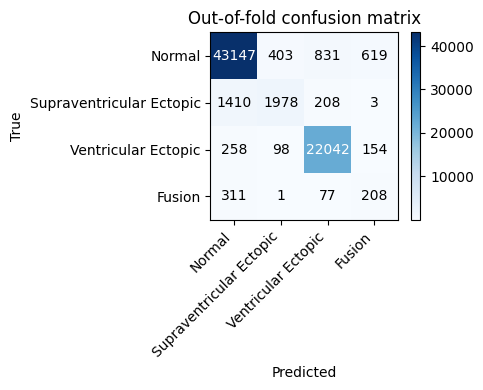

In [13]:
val_pred = (log_oof + bias).argmax(1)
print(f'Out-of-fold macro F1 (final): {f1_score(y_full, val_pred, average="macro"):.4f}\n')
print(classification_report(y_full, val_pred,
                            target_names=[class_names[i] for i in range(4)], digits=4))

cm = confusion_matrix(y_full, val_pred)
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(4)); ax.set_xticklabels(class_names.values(), rotation=45, ha='right')
ax.set_yticks(range(4)); ax.set_yticklabels(class_names.values())
ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title('Out-of-fold confusion matrix')
for i in range(4):
    for j in range(4):
        ax.text(j, i, cm[i, j], ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.colorbar(im); plt.tight_layout(); plt.show()

## 10. Predict on the test set and write `submission.csv`

In [14]:
test_pred = (log_test + bias).argmax(1)

print('Predicted test class distribution:')
print(pd.Series(test_pred).value_counts().sort_index())


# Degeneracy guard: a healthy model must not predict a single class for (nearly) everything.
_counts = np.bincount(test_pred, minlength=4)
_top = _counts.max() / _counts.sum()
assert (_counts > 0).sum() >= 2 and _top < 0.97, (
    f'Degenerate prediction ({_top:.1%} in one class) \u2014 the model collapsed; do NOT submit this. '
    f'Re-check training (val macroF1 should climb off 0.19). Class counts: {_counts.tolist()}')

submission = pd.DataFrame({'id': test_df['id'], 'label': test_pred})
assert (submission['id'].values == sample_sub['id'].values).all(), 'id order mismatch vs sample_submission!'
submission.to_csv('submission.csv', index=False)
submission.head()

Predicted test class distribution:
0    59016
1     1089
2     8606
3      203
Name: count, dtype: int64


,id,label
0,te_0000000,1
1,te_0000001,0
2,te_0000002,2
3,te_0000003,0
4,te_0000004,0
